# Onde há mais espécies marinhas na costa brasileira, ou onde há mais gente olhando?

**A decisão.** Quem planeja um levantamento de biodiversidade, uma área protegida ou um mapa de "pontos quentes"
costuma partir do que já foi registrado. A pergunta é se esse retrato mostra a biologia ou mostra o esforço de
coleta: onde houve mais expedições, mais universidades e mais gente com celular.

**Dados.** O OBIS (Ocean Biodiversity Information System) reúne registros de ocorrência de espécies marinhas do
mundo todo. Este estudo usa a Zona Econômica Exclusiva do Brasil cortada em 21 faixas de 2° de latitude, do Amapá
ao Rio Grande do Sul. A coleta usa só contagens agregadas (registros por espécie em cada faixa); nenhum registro
individual é baixado.

**O que o notebook mostra, em ordem:**

1. O esforço de coleta varia 85 vezes entre as faixas.
2. A riqueza bruta (espécies registradas) acompanha o esforço: é o concorrente simples, e ele engana.
3. A rarefação compara as faixas com a mesma régua, e o ranking muda.
4. Onde a correção falha: ela tira o efeito do *quanto* se coletou, mas não o de *quem* coletou e *o quê*.
5. Onde um novo levantamento renderia mais.
6. Estudo de caso: o mapa das tartarugas-marinhas.

O método está no pacote `vida_marinha` (pasta `src/`), com testes. O notebook só chama as funções e discute.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from vida_marinha import analise, dados, graficos

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_colwidth", 70)


def mostrar(figura):
    display(figura)
    plt.close(figura)


tabelas = dados.carregar()
tabela = analise.tabela_por_faixa(tabelas)
resumo = analise.resumo_geral(tabelas, tabela)
print(f"Coleta de {dados.data_da_coleta()}")
pd.Series(resumo, name="valor").to_frame()

Coleta de 2026-11-10


,valor
faixas,21.00
registros,"801,423.00"
registros_com_especie,"600,978.00"
especies_distintas,"10,349.00"
registros_faixa_mais_amostrada,"198,492.00"
registros_faixa_menos_amostrada,"2,332.00"
razao_de_esforco,85.12
n_ref,"1,500.00"


## 1. O esforço de coleta não é uniforme

São cerca de 800 mil registros e mais de 10 mil espécies. A faixa de 24°S a 22°S (litoral de São Paulo e do Rio de
Janeiro) tem 198 mil registros; a de 36°S a 34°S, 2,3 mil. Uma diferença de 85 vezes.

,registros,registros com espécie,conjuntos de dados,riqueza bruta,riqueza rarefeita,"rarefeita (2,5%)","rarefeita (97,5%)",completude,fração do maior conjunto
faixa,,,,,,,,,
4°N a 6°N,4209,1548,40,378,371.50,366.00,376.00,0.48,0.20
2°N a 4°N,4691,3947,56,601,377.22,361.00,396.00,0.67,0.37
0° a 2°N,21978,18682,79,1021,262.49,241.47,281.52,0.68,0.35
2°S a 0°,12242,9951,87,1126,481.12,458.48,503.52,0.79,0.21
4°S a 2°S,114064,55502,105,2197,382.47,357.00,406.52,0.70,0.44
6°S a 4°S,40247,24554,75,1517,313.82,292.00,334.00,0.55,0.31
8°S a 6°S,7852,6193,70,1244,604.20,580.48,627.05,0.66,0.21
10°S a 8°S,22637,17292,83,1808,600.65,574.00,630.52,0.68,0.30
12°S a 10°S,4736,3978,58,609,378.48,360.00,398.00,0.64,0.45


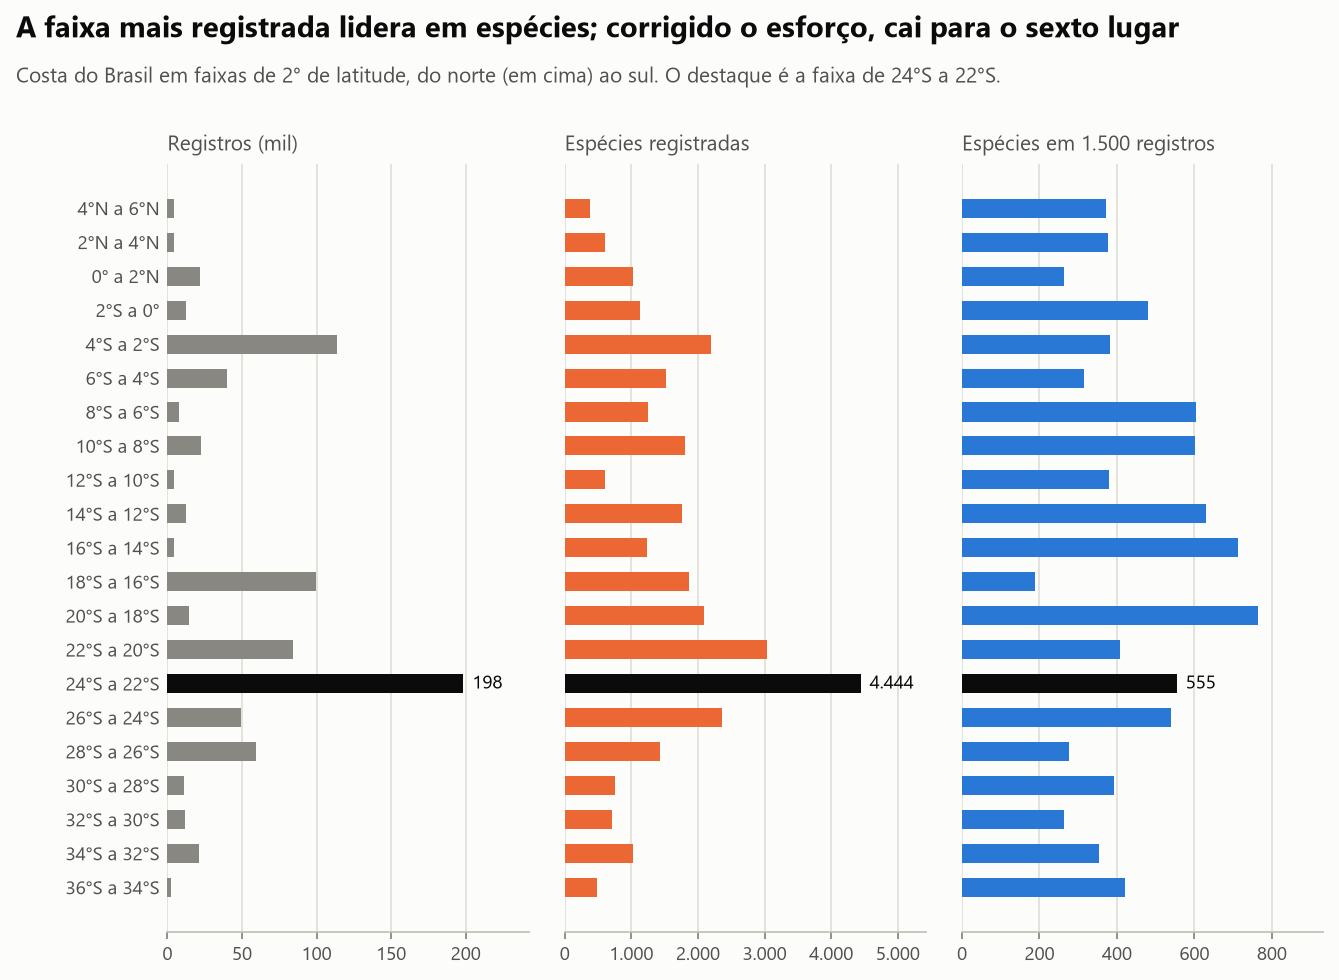

In [2]:
colunas = ["registros", "registros com espécie", "conjuntos de dados", "riqueza bruta", "riqueza rarefeita",
           "rarefeita (2,5%)", "rarefeita (97,5%)", "completude", "fração do maior conjunto"]
display(tabela[colunas])
mostrar(graficos.perfil_latitudinal(tabela, analise.N_REF))

## 2. O concorrente simples: contar espécies registradas

A leitura mais direta do banco é "a faixa com mais espécies registradas é a mais rica". Antes de aceitar, vale
conferir o quanto essa contagem acompanha o número de registros.

,rho,p,faixas
riqueza bruta x registros,0.82,0.00,21.00
riqueza rarefeita x registros,-0.20,0.39,21.00
riqueza bruta x riqueza rarefeita,0.35,0.12,21.00
riqueza rarefeita x fração do maior conjunto,-0.79,0.00,21.00
completude x registros,0.64,0.00,21.00
riqueza bruta x latitude,-0.12,0.59,21.00
riqueza rarefeita x latitude,-0.01,0.96,21.00
rarefeita em 1500 x rarefeita em 3000,1.00,0.00,19.00


,reta em escala log-log
inclinacao,0.43
intercepto,1.32
r2,0.74
fator_de_especies_ao_decuplicar_registros,2.69


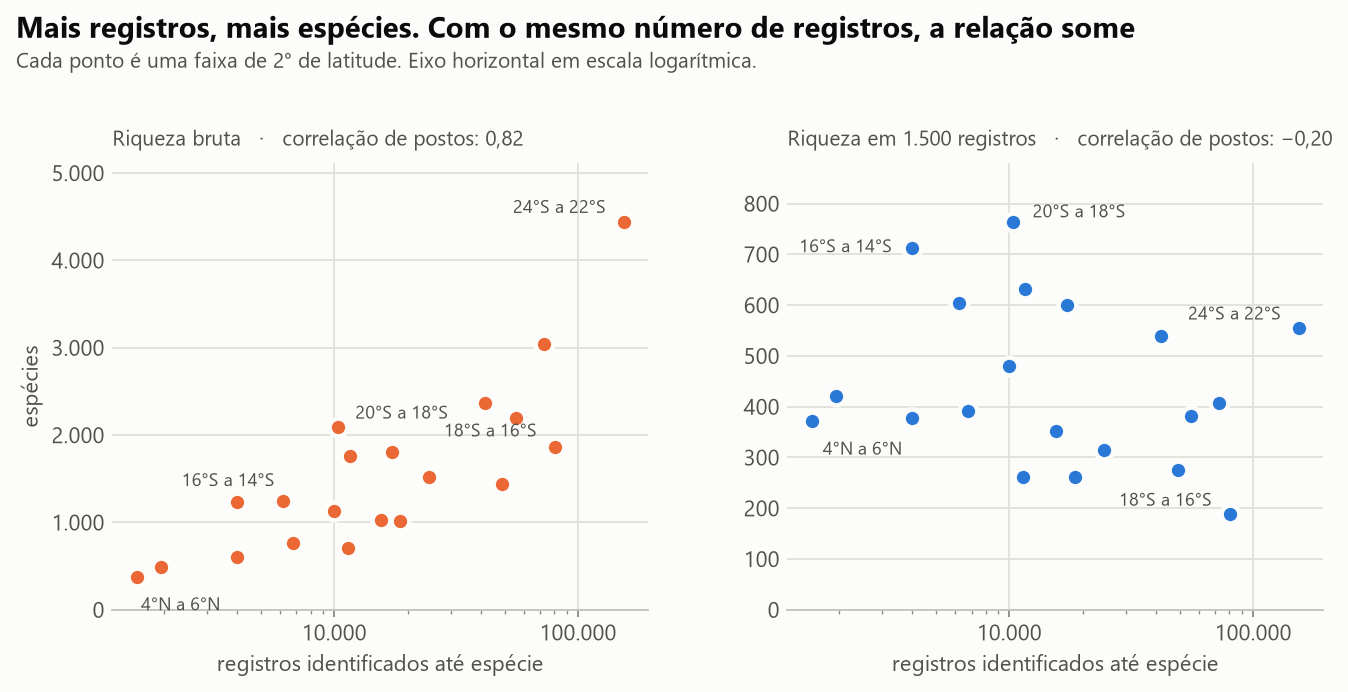

In [3]:
relacoes = analise.relacoes(tabela)
lei = analise.lei_de_esforco(tabela)
display(relacoes)
display(pd.Series(lei, name="reta em escala log-log").to_frame())
mostrar(graficos.riqueza_x_esforco(tabela, relacoes, analise.N_REF))

A riqueza bruta e o número de registros têm correlação de postos de 0,82. Em escala log-log, o número de registros
explica 74% da variação da riqueza bruta, e multiplicar os registros por 10 multiplica as espécies por cerca de 2,7.
Ou seja: o ranking de riqueza bruta é, em boa parte, um ranking de esforço.

Outro dado da mesma tabela: nem a riqueza bruta nem a corrigida mostram gradiente com a latitude neste recorte
(correlações perto de zero). O padrão clássico de "mais espécies perto do equador" não aparece nestes dados, e o
motivo provável é o mesmo: o que o banco mede é dominado por onde se coletou.

## 3. A mesma régua para todas: rarefação

A rarefação responde: **se cada faixa tivesse só 1.500 registros, sorteados ao acaso entre os que tem, quantas
espécies apareceriam?** A fórmula de Hurlbert dá esse valor esperado a partir da contagem de registros de cada
espécie, sem precisar sortear. 1.500 é o maior número que cabe em todas as 21 faixas.

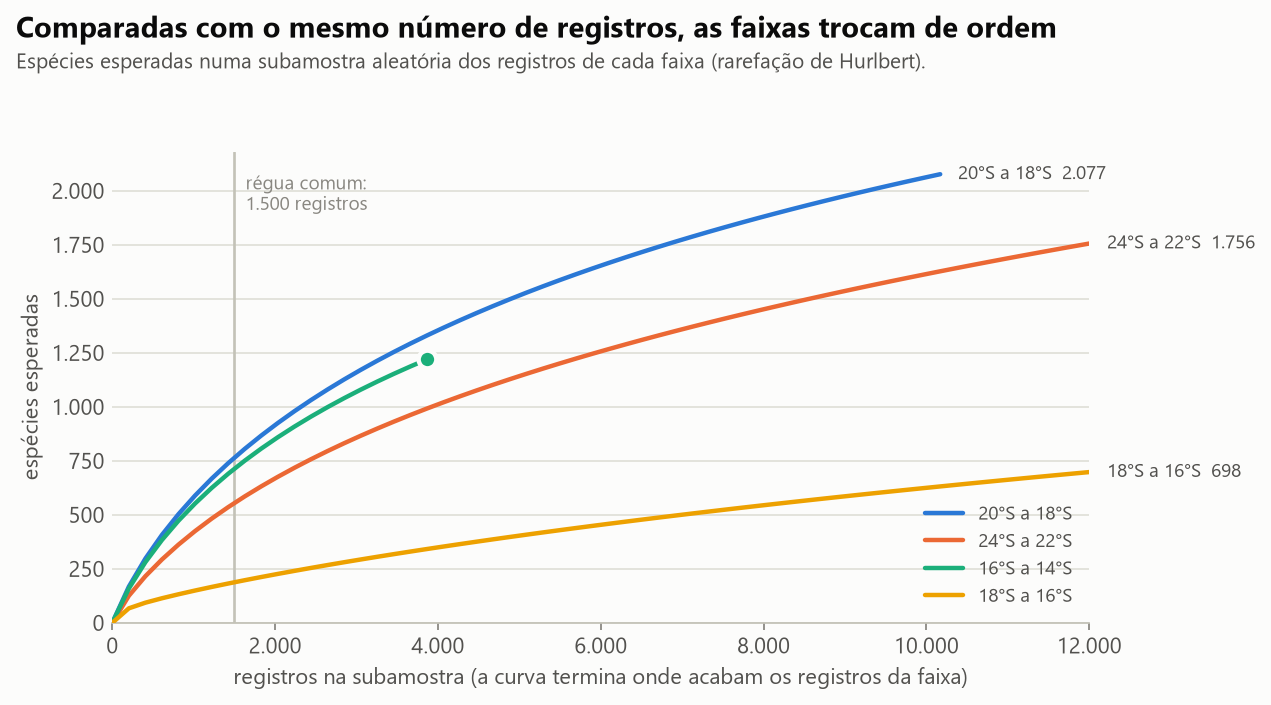

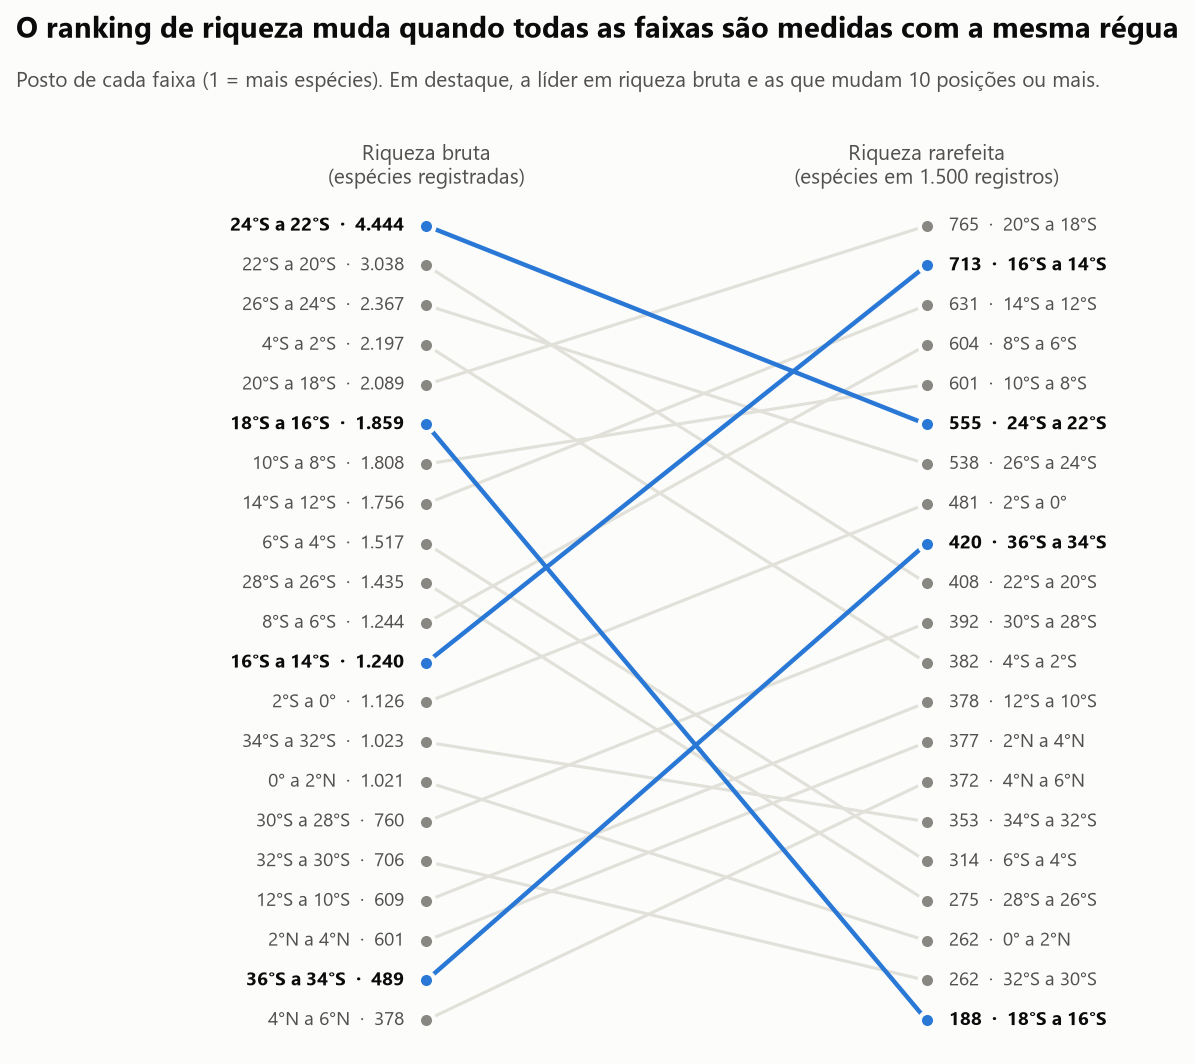

In [4]:
curvas = analise.curvas_de_rarefacao(tabelas, [-20, -24, -16, -18])
mostrar(graficos.curvas_de_rarefacao(curvas, analise.N_REF))
mostrar(graficos.troca_de_ranking(tabela, analise.N_REF))

In [5]:
movimento = tabela[["riqueza bruta", "posto pela riqueza bruta", "riqueza rarefeita",
                    "posto pela riqueza rarefeita", "mudança de posto"]]
movimento.sort_values("mudança de posto")

,riqueza bruta,posto pela riqueza bruta,riqueza rarefeita,posto pela riqueza rarefeita,mudança de posto
faixa,,,,,
18°S a 16°S,1859,6,187.72,21,-15
6°S a 4°S,1517,9,313.82,17,-8
22°S a 20°S,3038,2,407.54,10,-8
4°S a 2°S,2197,4,382.47,12,-8
28°S a 26°S,1435,10,275.37,18,-8
24°S a 22°S,4444,1,554.60,6,-5
0° a 2°N,1021,15,262.49,19,-4
26°S a 24°S,2367,3,538.48,7,-4
32°S a 30°S,706,17,262.45,20,-3


Com a mesma régua, a relação com o esforço desaparece (correlação de −0,20, indistinguível de zero com 21 faixas)
e o ranking muda:

- **24°S a 22°S**, a líder em riqueza bruta com 4.444 espécies, cai para o **6º lugar** (555 espécies em 1.500
  registros).
- **20°S a 18°S** (sul da Bahia e norte do Espírito Santo) sobe do 5º para o **1º** (765 espécies).
- **16°S a 14°S** sobe do 12º para o **2º**.
- **18°S a 16°S** (região de Abrolhos) despenca do 6º para o **último** lugar (188 espécies).

As faixas ao lado de cada valor na tabela vêm do sorteio de 300 subamostras e medem só o acaso do sorteio.

### O resultado resiste a duas trocas de método

In [6]:
peixes, peixes_x_todos = analise.so_peixes(tabelas, tabela)
print("Postos com 1.500 x com 3.000 registros:", relacoes.loc["rarefeita em 1500 x rarefeita em 3000"].round(3).to_dict())
print("Postos só com peixes x com todos os grupos:", {k: round(v, 3) for k, v in peixes_x_todos.items()})
peixes.sort_values("peixes, rarefeita", ascending=False).head(8)

Postos com 1.500 x com 3.000 registros: {'rho': 0.998, 'p': 0.0, 'faixas': 19.0}
Postos só com peixes x com todos os grupos: {'rho': 0.903, 'p': 0.0, 'faixas': 21}


,registros de peixes,espécies de peixes,"peixes, rarefeita"
faixa,,,
20°S a 18°S,3694,532,187.22
16°S a 14°S,554,220,184.96
14°S a 12°S,5435,548,174.59
8°S a 6°S,1766,332,174.50
10°S a 8°S,3647,433,169.83
2°S a 0°,4431,432,144.49
4°N a 6°N,555,174,140.63
36°S a 34°S,1079,209,125.23


Trocar a régua de 1.500 para 3.000 registros quase não altera a ordem (correlação de 0,998). Refazer a conta só com
peixes, o grupo mais registrado, também preserva o ranking (0,90). A troca de posições não é um artefato da régua
nem de um grupo biológico específico.

## 4. Onde a correção falha

A rarefação supõe que os registros de uma faixa são uma amostra aleatória da vida que existe ali. Não são. Cada
conjunto de dados tem um alvo: um programa de monitoramento de peixes recifais registra as mesmas espécies milhares
de vezes; um levantamento bentônico registra centenas de espécies poucas vezes cada.

In [7]:
dominancia = tabela[["registros", "riqueza rarefeita", "fração do maior conjunto", "maior conjunto"]]
display(dominancia.sort_values("fração do maior conjunto", ascending=False).head(8))
relacoes.loc[["riqueza rarefeita x fração do maior conjunto"]]

,registros,riqueza rarefeita,fração do maior conjunto,maior conjunto
faixa,,,,
18°S a 16°S,99430,187.72,0.60,ReefSYN | Standardized datasets of Brazilian reef diversity in spa...
32°S a 30°S,12019,262.45,0.48,Biological dataset for Pagrus pagrus fished along Southern Brazil
12°S a 10°S,4736,378.48,0.45,Northeast BR Mangrove
28°S a 26°S,59403,275.37,0.45,ReefSYN | Standardized datasets of Brazilian reef diversity in spa...
4°S a 2°S,114064,382.47,0.44,UNESCO eDNA expedition in Brazilian Atlantic Islands: Fernando de ...
2°N a 4°N,4691,377.22,0.37,Previous Fisheries REVIZEE Program
0° a 2°N,21978,262.49,0.35,Long-term Ecological Monitoring Research Brazilian Oceanic Islands...
6°S a 4°S,40247,313.82,0.31,ReefSYN | Standardized datasets of Brazilian reef diversity in spa...


,rho,p,faixas
riqueza rarefeita x fração do maior conjunto,-0.79,0.00,21.00


A riqueza rarefeita tem correlação de **−0,79** com a fração dos registros que vem do maior conjunto de dados da
faixa. Na faixa de 18°S a 16°S, um único conjunto de monitoramento recifal responde por 60% dos registros: muitos
registros das mesmas espécies achatam a curva de rarefação. O último lugar dessa faixa diz mais sobre o desenho do
monitoramento do que sobre a pobreza de espécies de Abrolhos, que é conhecida justamente pelos recifes.

Conclusão honesta: a rarefação corrige *quanto* se coletou, e isso basta para derrubar o ranking bruto. Mas o
ranking corrigido também não é "a verdade": ele carrega o viés de *quem* coletou e com que alvo. O banco responde
bem a "onde falta olhar" e mal a "onde há mais vida".

## 5. Onde um novo levantamento renderia mais

Duas medidas, ambas tiradas das espécies raras de cada faixa:

- **Completude:** fração das espécies estimadas (Chao1, um piso estatístico) que já foi registrada.
- **Espécies novas a cada 100 registros:** a chance de o próximo registro ser de uma espécie ainda não vista na
  faixa (Good-Turing) vezes 100.

In [8]:
analise.prioridade(tabela).head(8)

,registros,riqueza bruta,completude,espécies novas a cada 100 registros,fração do maior conjunto
faixa,,,,,
16°S a 14°S,4613,1240,0.62,15.34,0.16
36°S a 34°S,2332,489,0.55,13.99,0.30
4°N a 6°N,4209,378,0.48,13.44,0.20
8°S a 6°S,7852,1244,0.66,8.90,0.21
20°S a 18°S,14282,2089,0.69,8.05,0.13
12°S a 10°S,4736,609,0.64,6.86,0.45
2°N a 4°N,4691,601,0.67,6.59,0.37
14°S a 12°S,12811,1756,0.71,5.74,0.20


Nenhuma faixa passa de 79% de completude, e a menos completa (4°N a 6°N, no Amapá) está em 48%. Na faixa de 16°S a
14°S, cada 100 registros novos trazem em média 15 espécies ainda não registradas ali; na de 24°S a 22°S, menos de
1. Um registro novo no sul da Bahia rende cerca de 19 vezes mais em espécies novas para a faixa do que um no litoral
de São Paulo e do Rio.

"Nova" aqui quer dizer nova para a faixa neste banco, não nova para a ciência.

## 6. Estudo de caso: tartarugas-marinhas

As cinco espécies de tartarugas-marinhas que ocorrem no Brasil somam 1.770 registros na área. De onde eles vêm?

,registros,fração
tipo_de_fonte,,
ciência cidadã,968,0.55
telemetria,753,0.43
levantamento ou coleção,49,0.03


,tipo_de_fonte,ciência cidadã,levantamento ou coleção,telemetria,total
especie,nome popular,,,,
Chelonia mydas,tartaruga-verde,709,35,276,1020
Caretta caretta,tartaruga-cabeçuda,131,4,230,365
Eretmochelys imbricata,tartaruga-de-pente,91,1,60,152
Dermochelys coriacea,tartaruga-de-couro,14,9,122,145
Lepidochelys olivacea,tartaruga-oliva,23,0,65,88


,titulo,tipo_de_fonte,registros,fração
0,iNaturalist Research-grade Observations Marine Subset,ciência cidadã,942,0.53
1,Ascension Island green turtles migrations,telemetria,260,0.15
2,Study of the Biology of Sea Turtles in Brazil through Satellite Te...,telemetria,259,0.15
3,UCF - TAMAR - NOAA juvenile tracking (aggregated per 1-degree cell),telemetria,86,0.05
4,"Gabon 2007-08: Mayumba, Leatherback Turtles (aggregated per 1-degr...",telemetria,38,0.02
5,Brazil Trawl-Caught Turtles (aggregated per 1-degree cell),telemetria,35,0.02
6,"Observation.org, Nature data from around the World Marine Subset",ciência cidadã,24,0.01
7,Loggerheads Sea Turtles of Argentina (aggregated per 1-degree cell),telemetria,23,0.01


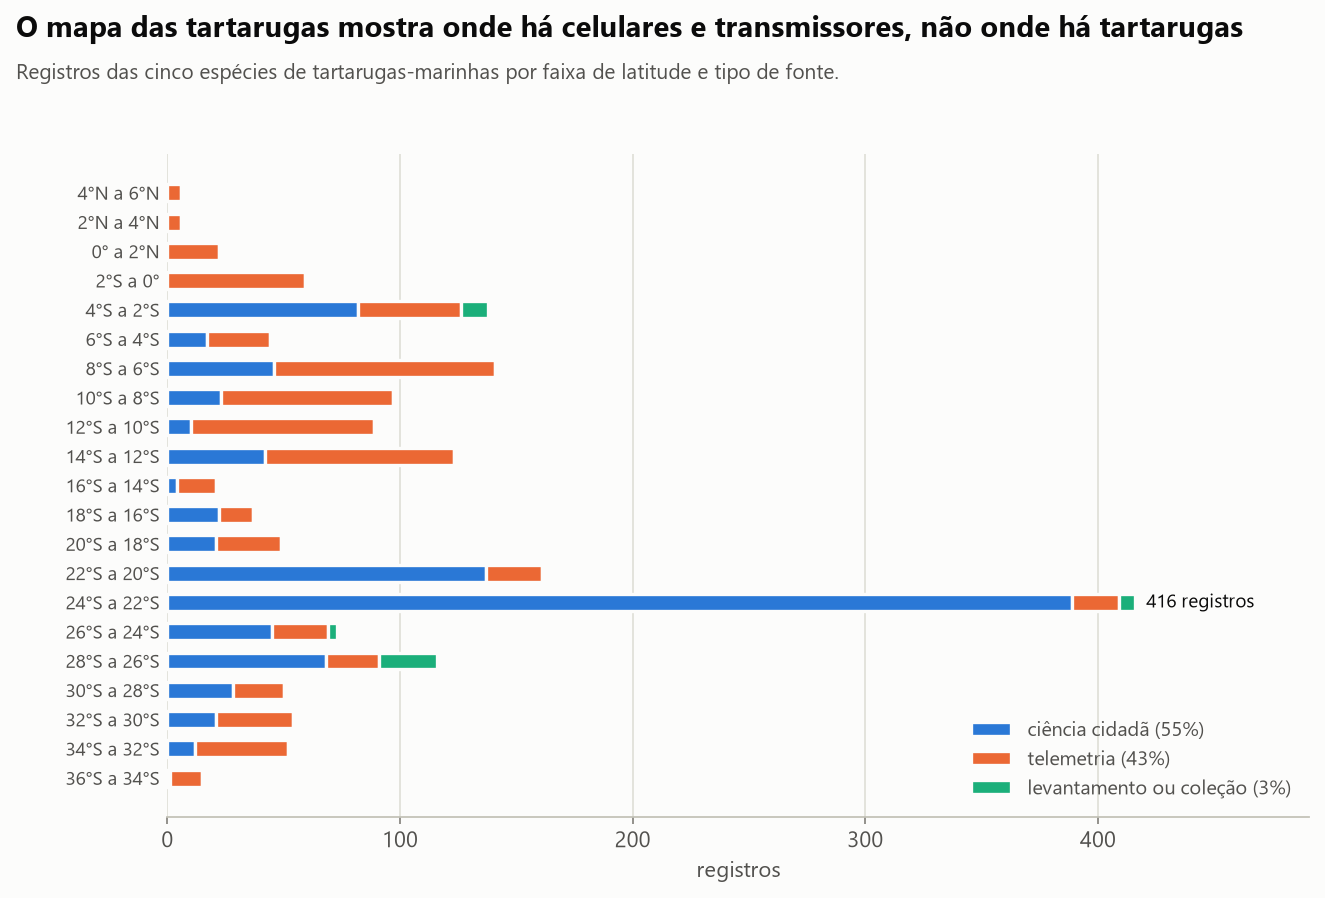

In [9]:
tart = analise.tartarugas(tabelas)
display(tart["por_tipo"])
display(tart["por_especie"])
display(tart["por_conjunto"].head(8))
mostrar(graficos.fontes_das_tartarugas(tart["por_faixa"], tart["por_tipo"]))

- **55% são ciência cidadã**, quase tudo de uma única plataforma de fotos. Eles se concentram onde há gente: 389 dos
  416 registros da faixa de 24°S a 22°S.
- **43% são telemetria:** posições de animais com transmissor, muitas já resumidas por célula de 1°. Um animal
  rastreado gera dezenas de pontos ao longo da rota, inclusive tartarugas marcadas em outros países que cruzam águas
  brasileiras.
- **Só 3%** vêm de levantamentos ou coleções.

O mapa de registros de tartarugas mostra, portanto, onde há celulares e por onde passaram animais com transmissor.
Ele não permite dizer onde há mais tartarugas, nem onde elas desovam. Os dados dos programas de monitoramento de
praia, que responderiam a isso, não estão neste banco.

## Conclusões

1. **Riqueza bruta mede esforço.** A correlação com o número de registros é 0,82; decuplicar os registros multiplica
   as espécies por 2,7.
2. **Com a mesma régua, o ranking muda.** A faixa mais registrada cai do 1º para o 6º lugar; a de 20°S a 18°S
   assume a liderança.
3. **A correção tem limite.** A riqueza rarefeita depende de quão concentrados os registros estão num único
   conjunto de dados (correlação de −0,79).
4. **O banco serve para decidir onde olhar.** As faixas com mais retorno por registro novo estão no sul da Bahia,
   no extremo sul e no extremo norte.
5. **Para tartarugas, 97% dos registros são ciência cidadã ou telemetria.**

## Limitações

- **Registro não é abundância.** Um registro diz que alguém viu ou coletou a espécie ali. Mil registros de uma
  espécie podem ser mil indivíduos ou o mesmo ponto de monitoramento visitado mil vezes.
- **Registros não são amostra aleatória**, que é o que a rarefação, o Chao1 e o Good-Turing supõem. Os números
  corrigidos são comparações mais justas, não estimativas da riqueza real.
- **Viés de acesso e de instituição.** A costa perto de universidades, portos e cidades grandes é mais amostrada, e
  a rarefação não corrige o que nunca foi coletado.
- **Qualidade taxonômica.** Um quarto dos registros não chega ao nível de espécie e ficou fora das contas de
  riqueza. Grupos difíceis de identificar aparecem menos do que existem.
- **Faixas com pouco dado.** Duas faixas têm menos de 2 mil registros com espécie; a régua de 1.500 usa quase tudo
  o que elas têm.
- **Recorte geográfico.** Faixas de 2° misturam costa, plataforma e mar aberto, e a área de cada faixa dentro da
  ZEE é diferente. O estudo não normaliza por área.
- **Classificação das fontes** de tartarugas por palavras do título do conjunto de dados: é aproximada.
- **Foto de um dia.** O OBIS cresce continuamente; os números são da data da coleta.